[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch16_KidsLab05_CIFAR10_CNN.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 16: Building Real CNNs: Fashion-MNIST and CIFAR-10** (Part III: Seeing). Also used in Chapters 10, 15. This lab comes from the simplified video course for kids, kept for comparison.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=16](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=16)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 🎨 CIFAR-10 CNN: See Inside the AI Brain!
## Visualize Every Layer + Upload YOUR Photos!

**What you'll learn:**
1. Explore CIFAR-10 colorful images
2. Build a CNN step-by-step
3. **SEE what each layer learns!**
4. Train the network
5. Upload photos and classify!

**10 Categories:**
✈️ Airplane | 🚗 Automobile | 🐦 Bird | 🐱 Cat | 🦌 Deer  
🐕 Dog | 🐸 Frog | 🐴 Horse | 🚢 Ship | 🚚 Truck

---

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Trains until it stops improving.** The original stopped after a fixed 15 epochs while training and validation accuracy were both still rising. Now it trains for up to 60 epochs with early stopping on the validation loss (patience 5, best weights restored).
> * **Honest feature maps.** Each map used to get its own colour scale, so a filter that barely responded looked as bright as the strongest one. Every figure now shares one scale, and filters with no response at all are labelled *silent*.
> * **Runs outside Colab**, with your own photos in `MY_IMAGES` or a demo photo; photos are now cropped to a centred square before shrinking to 32×32, instead of being squashed.
> * Plot titles showed the class emoji, which Matplotlib's default font cannot draw (empty boxes); they now show the class name (21 lines). Printed text keeps its emoji.
> * `keras.utils.set_random_seed(42)` makes the run repeatable; one log line per epoch.

## 📦 Cell 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

# (the upload helper, further down, handles Colab and non-Colab)

keras.utils.set_random_seed(42)   # Python, NumPy and TensorFlow in one call: the same run every time

print("✅ Libraries loaded!")
print(f"TensorFlow: {tf.__version__}")
print(f"Keras: {keras.__version__}")

✅ Libraries loaded!
TensorFlow: 2.21.0
Keras: 3.14.1


---
## 📊 Cell 2: Load CIFAR-10 Dataset

In [2]:
print("📥 Loading CIFAR-10 dataset...\n")

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Class names and emojis
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
class_emojis = ['✈️', '🚗', '🐦', '🐱', '🦌', '🐕', '🐸', '🐴', '🚢', '🚚']

print(f"✅ CIFAR-10 loaded!")
print(f"Training images: {X_train.shape[0]:,}")
print(f"Test images: {X_test.shape[0]:,}")
print(f"Image size: {X_train.shape[1]}×{X_train.shape[2]} pixels")
print(f"Color channels: {X_train.shape[3]} (RGB)")
print(f"\n🎨 Object Categories:")
for i, (emoji, name) in enumerate(zip(class_emojis, class_names)):
    print(f"  {emoji} {i}: {name}")

📥 Loading CIFAR-10 dataset...



✅ CIFAR-10 loaded!
Training images: 50,000
Test images: 10,000
Image size: 32×32 pixels
Color channels: 3 (RGB)

🎨 Object Categories:
  ✈️ 0: Airplane
  🚗 1: Automobile
  🐦 2: Bird
  🐱 3: Cat
  🦌 4: Deer
  🐕 5: Dog
  🐸 6: Frog
  🐴 7: Horse
  🚢 8: Ship
  🚚 9: Truck


---
## 🎨 Cell 3: Explore the Dataset

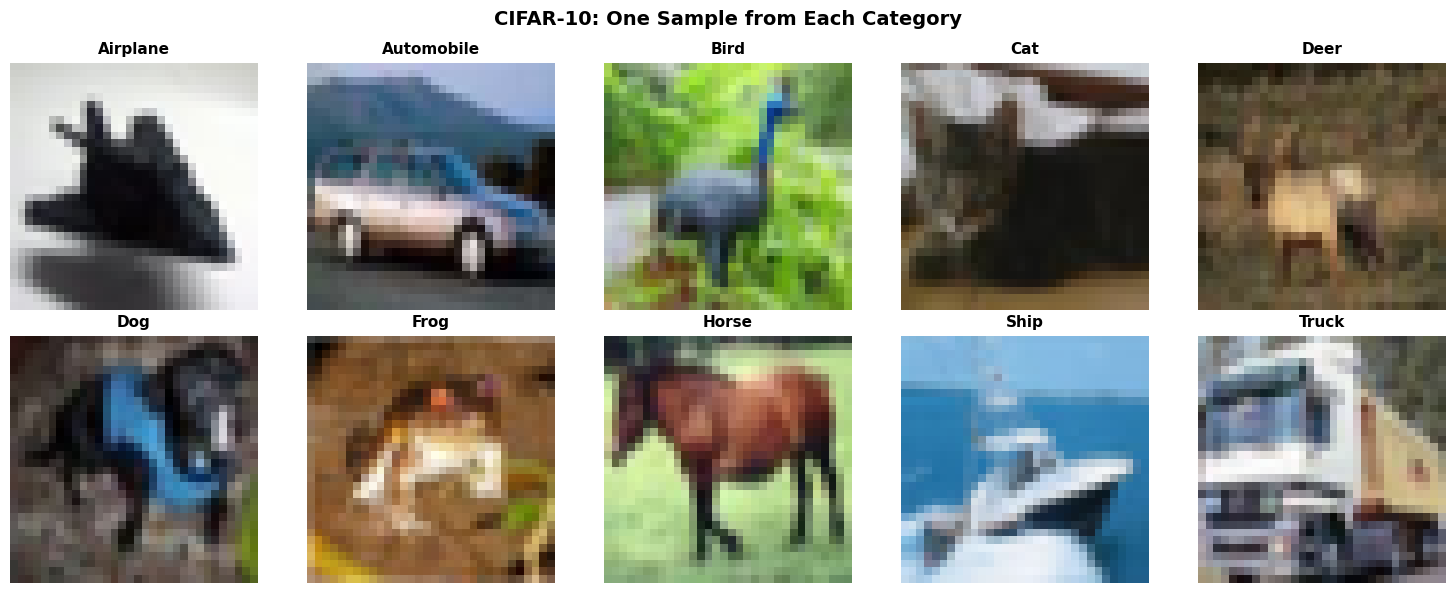


💡 Notice: Images are only 32×32 pixels - quite small!
   This makes classification challenging, even for humans.


In [3]:
# Show sample images from each category
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i in range(10):
    # Find first image of this class
    idx = np.where(y_train.flatten() == i)[0][0]
    axes[i].imshow(X_train[idx])
    axes[i].set_title(f"{class_names[i]}", fontsize=11, fontweight='bold')
    axes[i].axis('off')

plt.suptitle('CIFAR-10: One Sample from Each Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Notice: Images are only 32×32 pixels - quite small!")
print("   This makes classification challenging, even for humans.")

---
## 🔧 Cell 4: Preprocess Data

In [4]:
# Normalize pixel values to 0-1 range
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

# Convert labels to categorical (one-hot encoding)
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

print("✅ Data preprocessed!")
print(f"\nBefore normalization: pixels range from {X_train.min()} to {X_train.max()}")
print(f"After normalization: pixels range from {X_train_norm.min():.1f} to {X_train_norm.max():.1f}")
print(f"\nLabel shape: {y_train.shape} → {y_train_cat.shape}")
print(f"Example: Label 3 (Cat) → {y_train_cat[np.where(y_train.flatten()==3)[0][0]]}")

✅ Data preprocessed!

Before normalization: pixels range from 0 to 255
After normalization: pixels range from 0.0 to 1.0

Label shape: (50000, 1) → (50000, 10)
Example: Label 3 (Cat) → [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


---
## 🏗️ Cell 5: Build the CNN Model (Functional API)

**Using Functional API** to ensure layer visualization works!

Our CNN has 3 convolutional blocks:
- **Block 1**: 32 filters → edges and colors
- **Block 2**: 64 filters → patterns and textures  
- **Block 3**: 128 filters → object parts

In [5]:
# ============================================================================
# 🏗️ BUILD CNN USING FUNCTIONAL API (Required for layer visualization!)
# ============================================================================

# Define input layer explicitly
inputs = keras.Input(shape=(32, 32, 3), name='input_layer')

# Block 1: Edge & Color Detection
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_1')(inputs)
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_2')(x)
x = layers.MaxPooling2D((2, 2), name='pool1')(x)
x = layers.Dropout(0.25, name='dropout1')(x)

# Block 2: Pattern & Texture Detection
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_1')(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_2')(x)
x = layers.MaxPooling2D((2, 2), name='pool2')(x)
x = layers.Dropout(0.25, name='dropout2')(x)

# Block 3: Object Part Detection
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_1')(x)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_2')(x)
x = layers.MaxPooling2D((2, 2), name='pool3')(x)
x = layers.Dropout(0.25, name='dropout3')(x)

# Classification Head
x = layers.Flatten(name='flatten')(x)
x = layers.Dense(512, activation='relu', name='dense1')(x)
x = layers.Dropout(0.5, name='dropout4')(x)
outputs = layers.Dense(10, activation='softmax', name='output')(x)

# Create model
model = keras.Model(inputs=inputs, outputs=outputs, name='CIFAR10_CNN')

# Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Model built using Functional API!")
print("   (This ensures layer visualization will work correctly)")
print("\n📊 Model Summary:")
model.summary()

✅ Model built using Functional API!
   (This ensures layer visualization will work correctly)

📊 Model Summary:


Model: "CIFAR10_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (Dropout)              │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout4 (Dropout)              │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,341,226 (5.12 MB)

 Trainable params: 1,341,226 (5.12 MB)

 Non-trainable params: 0 (0.00 B)

---
## 🔬 Cell 6: Create Layer Visualization Models

We create these **before training** so they're ready for visualization!

In [6]:
# ============================================================================
# 🔬 CREATE LAYER VISUALIZATION MODELS
# ============================================================================

# Create models to extract intermediate layer outputs
layer1_model = keras.Model(
    inputs=model.input,
    outputs=model.get_layer('conv1_1').output,
    name='layer1_extractor'
)

layer2_model = keras.Model(
    inputs=model.input,
    outputs=model.get_layer('conv2_1').output,
    name='layer2_extractor'
)

layer3_model = keras.Model(
    inputs=model.input,
    outputs=model.get_layer('conv3_1').output,
    name='layer3_extractor'
)

print("✅ Layer visualization models created!")
print(f"\nLayer 1 output shape: {layer1_model.output_shape}")
print(f"Layer 2 output shape: {layer2_model.output_shape}")
print(f"Layer 3 output shape: {layer3_model.output_shape}")

✅ Layer visualization models created!

Layer 1 output shape: (None, 32, 32, 32)
Layer 2 output shape: (None, 16, 16, 64)
Layer 3 output shape: (None, 8, 8, 128)


---
## 📐 Cell 7: Visualize Architecture

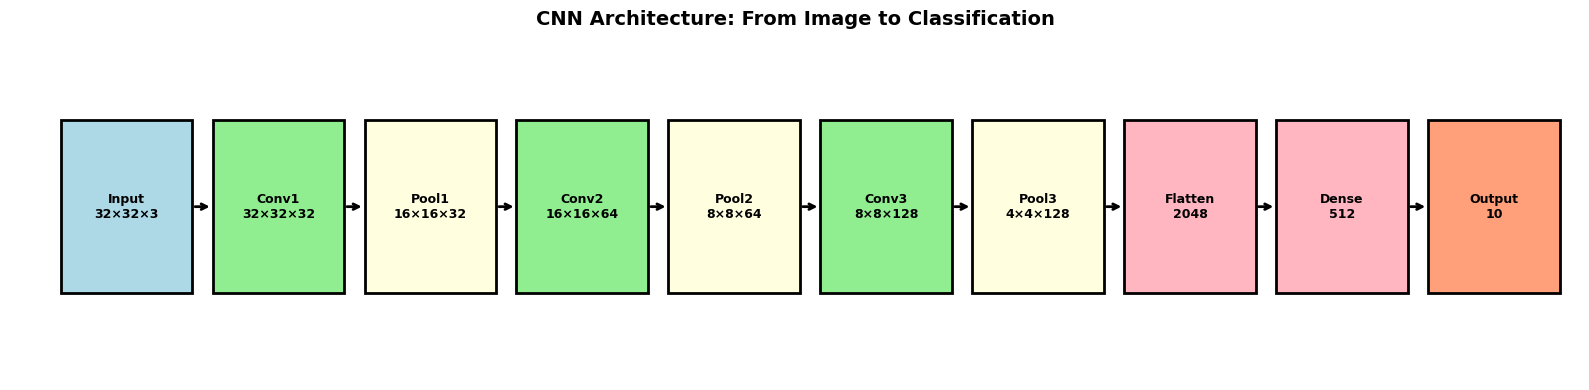


💡 Notice how the spatial size DECREASES while depth INCREASES!
   32×32×3 → 16×16×32 → 8×8×64 → 4×4×128 → 10 classes


In [7]:
# Create architecture diagram
fig, ax = plt.subplots(figsize=(16, 4))

# Define layer info
layer_info = [
    ('Input\n32×32×3', 'lightblue'),
    ('Conv1\n32×32×32', 'lightgreen'),
    ('Pool1\n16×16×32', 'lightyellow'),
    ('Conv2\n16×16×64', 'lightgreen'),
    ('Pool2\n8×8×64', 'lightyellow'),
    ('Conv3\n8×8×128', 'lightgreen'),
    ('Pool3\n4×4×128', 'lightyellow'),
    ('Flatten\n2048', 'lightpink'),
    ('Dense\n512', 'lightpink'),
    ('Output\n10', 'lightsalmon')
]

# Draw boxes
for i, (label, color) in enumerate(layer_info):
    rect = plt.Rectangle((i * 1.5, 0), 1.3, 1, facecolor=color, edgecolor='black', linewidth=2)
    ax.add_patch(rect)
    ax.text(i * 1.5 + 0.65, 0.5, label, ha='center', va='center', fontsize=9, fontweight='bold')

    # Draw arrows
    if i < len(layer_info) - 1:
        ax.annotate('', xy=(i * 1.5 + 1.5, 0.5), xytext=(i * 1.5 + 1.3, 0.5),
                   arrowprops=dict(arrowstyle='->', color='black', lw=2))

ax.set_xlim(-0.5, 15)
ax.set_ylim(-0.5, 1.5)
ax.axis('off')
ax.set_title('CNN Architecture: From Image to Classification', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Notice how the spatial size DECREASES while depth INCREASES!")
print("   32×32×3 → 16×16×32 → 8×8×64 → 4×4×128 → 10 classes")

---
## 🚀 Cell 8: Train the Model

⏱️ This takes a while: switch on a GPU in Colab (Runtime → Change runtime type → GPU) if it is slow.

**Early stopping** decides when to stop: it watches the validation loss, stops when it has not improved for
5 epochs, and puts back the weights from the best epoch. (The first version of this notebook stopped after a
fixed 15 epochs, while training and validation accuracy were both still rising: it had room left.)

In [8]:
print("🚀 Training CNN on CIFAR-10 (up to 60 epochs, stopping early)...\n")
print("   Go to Runtime → Change runtime type → GPU if slow\n")

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train with validation
history = model.fit(
    X_train_norm, y_train_cat,
    batch_size=64,
    epochs=60,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=2            # one line per epoch
)

epochs_run = len(history.history['loss'])
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f"\n✅ Training complete after {epochs_run} epochs; best validation loss at epoch {best_epoch} (weights restored).")

🚀 Training CNN on CIFAR-10 (up to 60 epochs, stopping early)...

   Go to Runtime → Change runtime type → GPU if slow



Epoch 1/60


704/704 - 38s - 53ms/step - accuracy: 0.3898 - loss: 1.6317 - val_accuracy: 0.4692 - val_loss: 1.4396


Epoch 2/60


704/704 - 32s - 45ms/step - accuracy: 0.5642 - loss: 1.2091 - val_accuracy: 0.6434 - val_loss: 0.9811


Epoch 3/60


... (34 outputs left out)

704/704 - 34s - 49ms/step - accuracy: 0.8245 - loss: 0.4950 - val_accuracy: 0.8018 - val_loss: 0.6172


Epoch 21/60


704/704 - 32s - 46ms/step - accuracy: 0.8245 - loss: 0.4979 - val_accuracy: 0.7988 - val_loss: 0.6125



✅ Training complete after 21 epochs; best validation loss at epoch 16 (weights restored).


---
## 📈 Cell 9: Training History

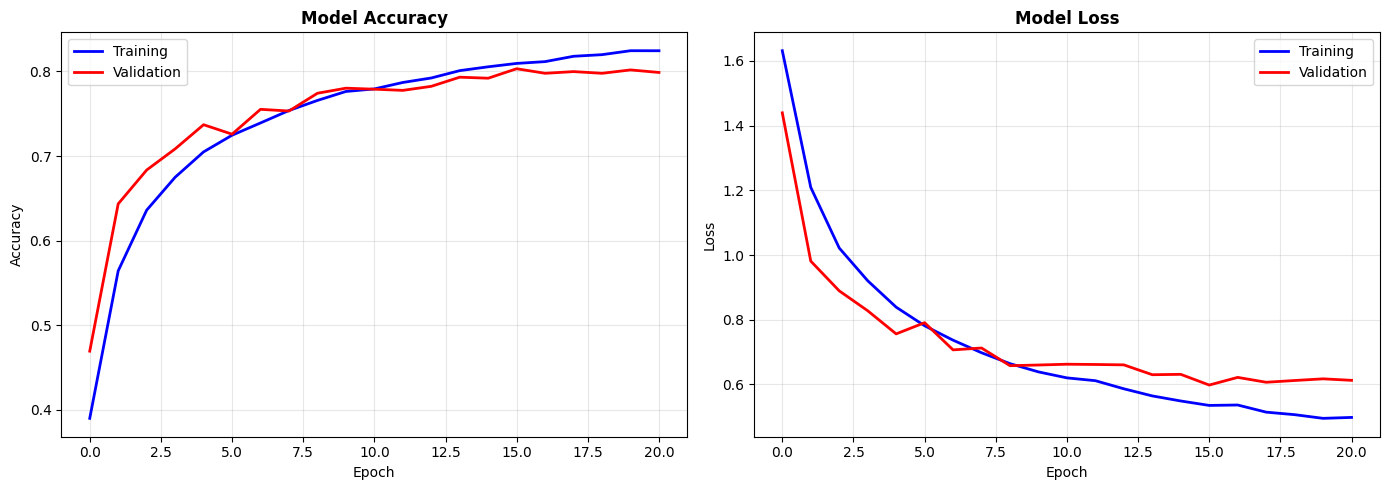


🎯 Test Accuracy: 79.11%


In [9]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'], 'b-', label='Training', linewidth=2)
axes[0].plot(history.history['val_accuracy'], 'r-', label='Validation', linewidth=2)
axes[0].set_title('Model Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history.history['loss'], 'b-', label='Training', linewidth=2)
axes[1].plot(history.history['val_loss'], 'r-', label='Validation', linewidth=2)
axes[1].set_title('Model Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Evaluate on test set
test_loss, test_acc = model.evaluate(X_test_norm, y_test_cat, verbose=0)
print(f"\n🎯 Test Accuracy: {test_acc*100:.2f}%")

---
# 🔬 LAYER VISUALIZATION

Now the exciting part! Let's see what each layer has learned!

> **Reading the feature maps:** within one figure, every map uses the **same colour scale**: dark = 0,
> brightest yellow = the strongest response of any map in the figure. A filter that barely reacts to this
> image really does look dark, and one that does not react at all is labelled *silent*. (If each map had its
> own scale, as in the first version of this notebook, a filter answering 0.01 would look exactly as bright as
> one answering 5.)

---
## 🔬 Cell 10: Visualize Layer 1 - Edge & Color Detectors

🔬 Visualizing Layer 1: Edge & Color Detectors

Test image: 🐸 Frog

Layer 1 output shape: (1, 32, 32, 32)
  → 32 feature maps of 32×32 pixels


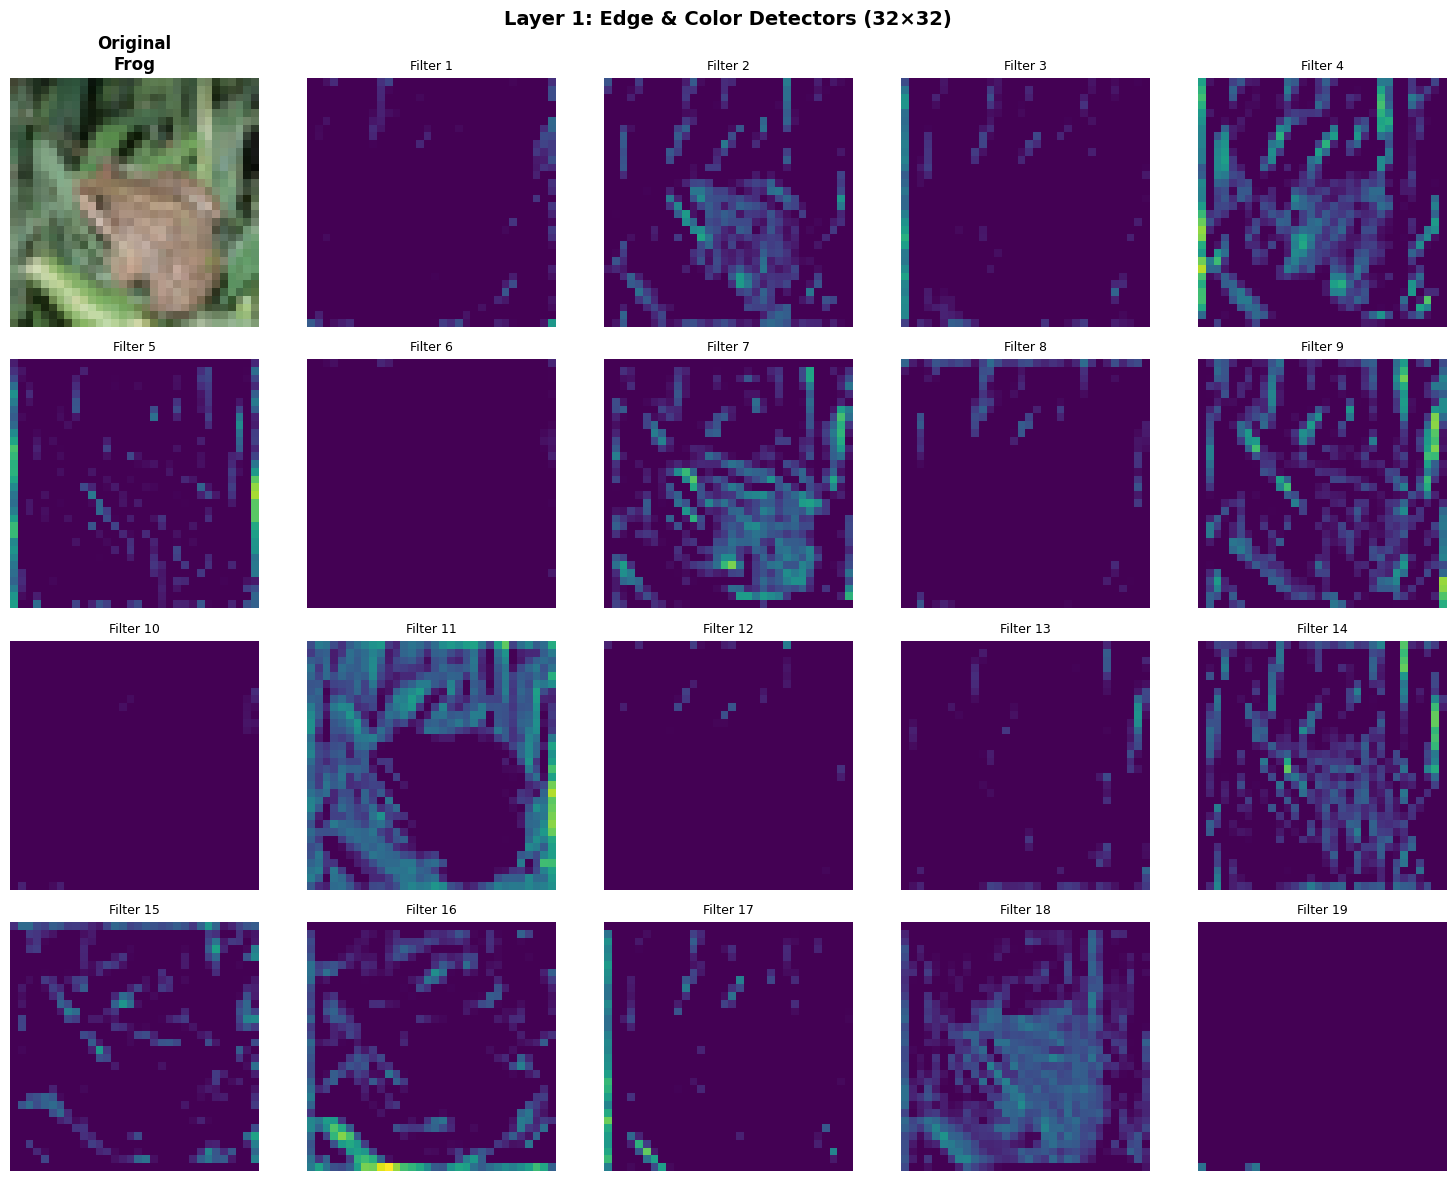


💡 What to observe:
   • Some filters detect EDGES (horizontal, vertical, diagonal)
   • Some filters respond to specific COLORS
   • Feature maps still resemble the original shape!

🔄 Try changing test_idx above to see different images!


In [10]:
# Pick a test image
test_idx = 4  # 🔄 Change this number to try different images!
test_image = X_test_norm[test_idx:test_idx+1]  # Keep batch dimension
test_label = y_test[test_idx][0]

print(f"🔬 Visualizing Layer 1: Edge & Color Detectors\n")
print(f"Test image: {class_emojis[test_label]} {class_names[test_label]}\n")

# Get activations using the pre-created layer model
layer1_activations = layer1_model.predict(test_image, verbose=0)

print(f"Layer 1 output shape: {layer1_activations.shape}")
print(f"  → {layer1_activations.shape[3]} feature maps of {layer1_activations.shape[1]}×{layer1_activations.shape[2]} pixels")

# Visualize the first 19 feature maps, all on ONE colour scale (0 = dark, the strongest response = bright)
vmax = layer1_activations[0, :, :, :19].max()
fig, axes = plt.subplots(4, 5, figsize=(15, 12))

# Original image
axes[0, 0].imshow(X_test[test_idx])
axes[0, 0].set_title(f'Original\n{class_names[test_label]}', fontweight='bold')
axes[0, 0].axis('off')

# Feature maps
for i in range(19):
    row = (i + 1) // 5
    col = (i + 1) % 5
    axes[row, col].imshow(layer1_activations[0, :, :, i], cmap='viridis', vmin=0, vmax=vmax)
    axes[row, col].set_title(f'Filter {i+1}' + ('  (silent)' if layer1_activations[0, :, :, i].max() == 0 else ''), fontsize=9)
    axes[row, col].axis('off')

plt.suptitle('Layer 1: Edge & Color Detectors (32×32)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 What to observe:")
print("   • Some filters detect EDGES (horizontal, vertical, diagonal)")
print("   • Some filters respond to specific COLORS")
print("   • Feature maps still resemble the original shape!")
print("\n🔄 Try changing test_idx above to see different images!")

---
## 🔬 Cell 11: Visualize Layer 2 - Pattern & Texture Detectors

🔬 Visualizing Layer 2: Pattern & Texture Detectors

Test image: 🐸 Frog

Layer 2 output shape: (1, 16, 16, 64)
  → 64 feature maps of 16×16 pixels


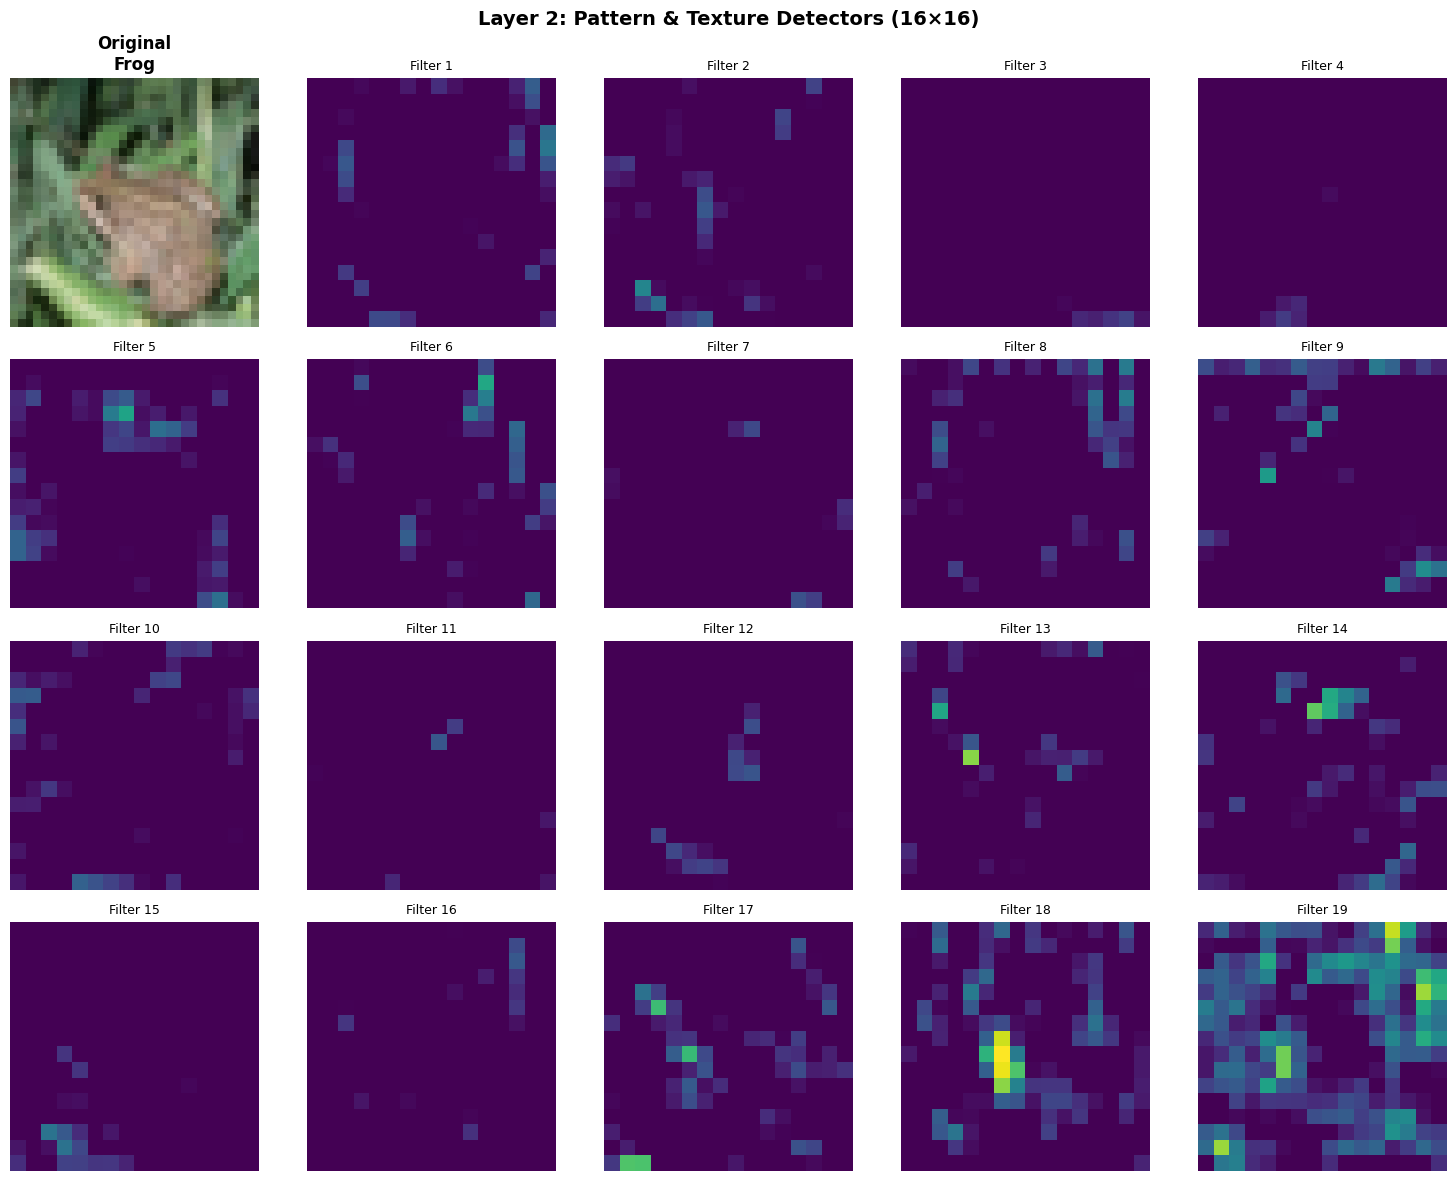


💡 What to observe:
   • Feature maps are SMALLER (16×16) - pooling reduced size
   • Patterns are more ABSTRACT - combinations of edges
   • Some filters highlight specific TEXTURES (fur, feathers, metal)


In [11]:
print(f"🔬 Visualizing Layer 2: Pattern & Texture Detectors\n")
print(f"Test image: {class_emojis[test_label]} {class_names[test_label]}\n")

# Get activations
layer2_activations = layer2_model.predict(test_image, verbose=0)

print(f"Layer 2 output shape: {layer2_activations.shape}")
print(f"  → {layer2_activations.shape[3]} feature maps of {layer2_activations.shape[1]}×{layer2_activations.shape[2]} pixels")

# Visualize the first 19 feature maps, all on ONE colour scale (0 = dark, the strongest response = bright)
vmax = layer2_activations[0, :, :, :19].max()
fig, axes = plt.subplots(4, 5, figsize=(15, 12))

# Original image
axes[0, 0].imshow(X_test[test_idx])
axes[0, 0].set_title(f'Original\n{class_names[test_label]}', fontweight='bold')
axes[0, 0].axis('off')

# Feature maps
for i in range(19):
    row = (i + 1) // 5
    col = (i + 1) % 5
    axes[row, col].imshow(layer2_activations[0, :, :, i], cmap='viridis', vmin=0, vmax=vmax)
    axes[row, col].set_title(f'Filter {i+1}' + ('  (silent)' if layer2_activations[0, :, :, i].max() == 0 else ''), fontsize=9)
    axes[row, col].axis('off')

plt.suptitle('Layer 2: Pattern & Texture Detectors (16×16)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 What to observe:")
print("   • Feature maps are SMALLER (16×16) - pooling reduced size")
print("   • Patterns are more ABSTRACT - combinations of edges")
print("   • Some filters highlight specific TEXTURES (fur, feathers, metal)")

---
## 🔬 Cell 12: Visualize Layer 3 - Object Part Detectors

🔬 Visualizing Layer 3: Object Part Detectors

Test image: 🐸 Frog

Layer 3 output shape: (1, 8, 8, 128)
  → 128 feature maps of 8×8 pixels


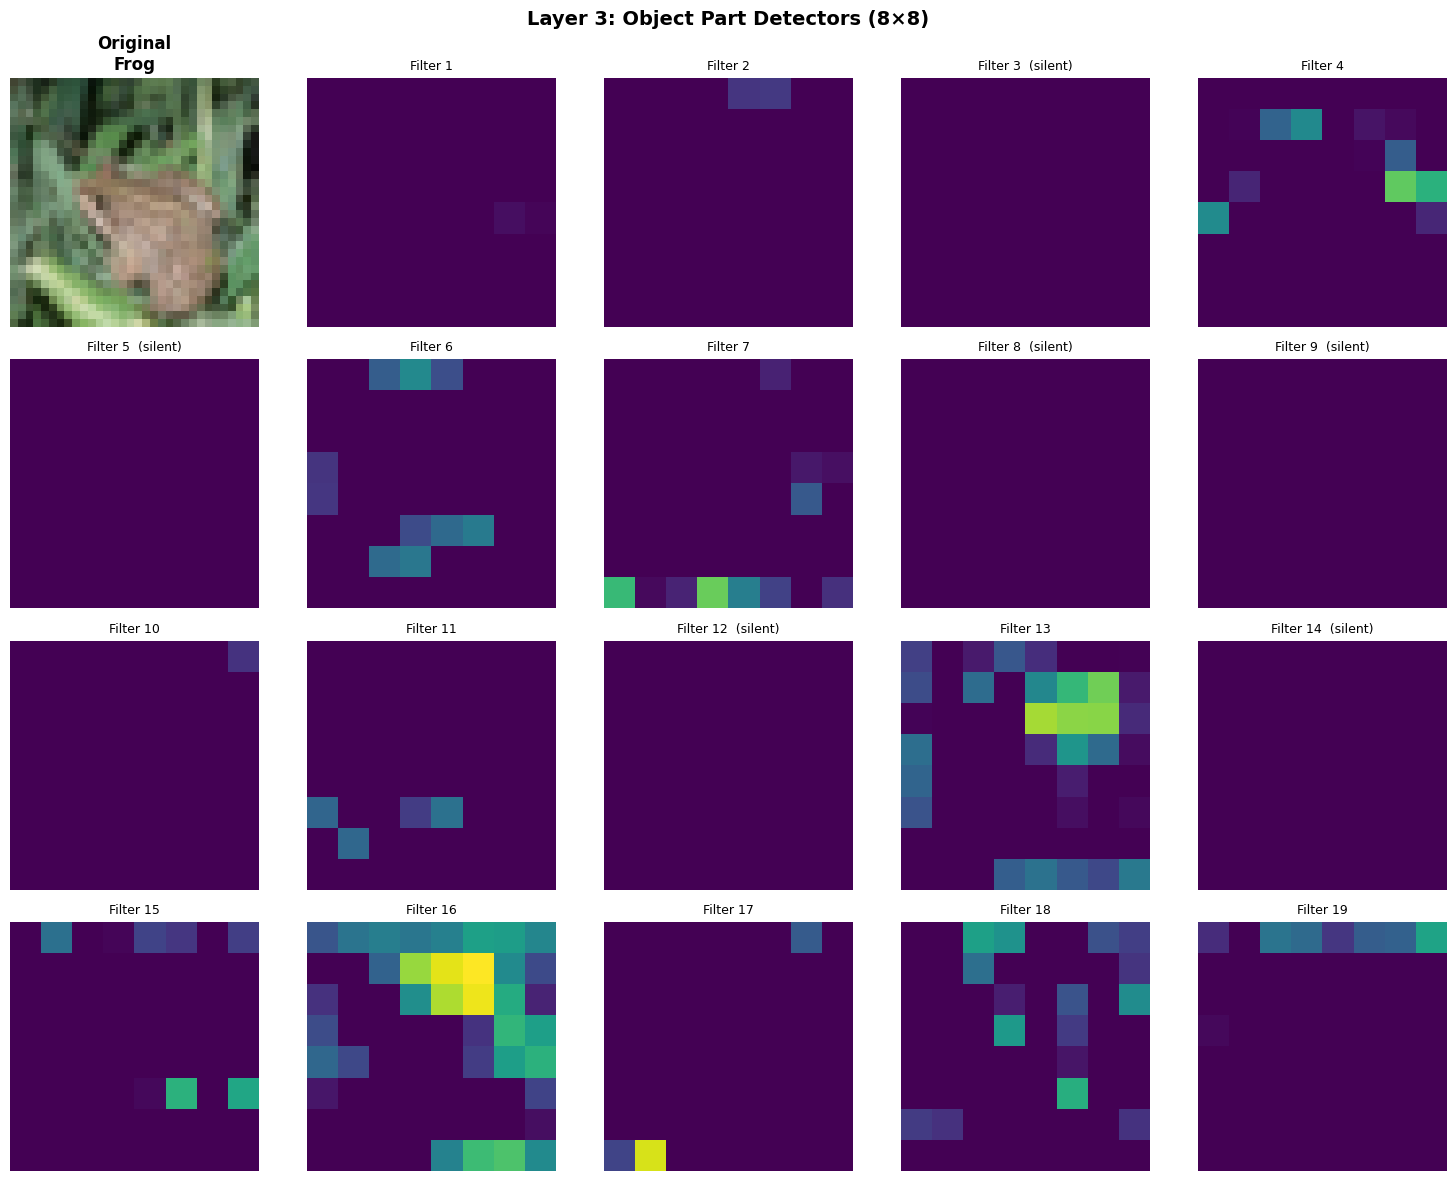


💡 What to observe:
   • Feature maps are even SMALLER (8×8)
   • Highly ABSTRACT - hard to see original image
   • Each filter detects specific OBJECT PARTS!
   • This is what the CNN uses to make its final decision!


In [12]:
print(f"🔬 Visualizing Layer 3: Object Part Detectors\n")
print(f"Test image: {class_emojis[test_label]} {class_names[test_label]}\n")

# Get activations
layer3_activations = layer3_model.predict(test_image, verbose=0)

print(f"Layer 3 output shape: {layer3_activations.shape}")
print(f"  → {layer3_activations.shape[3]} feature maps of {layer3_activations.shape[1]}×{layer3_activations.shape[2]} pixels")

# Visualize the first 19 feature maps, all on ONE colour scale (0 = dark, the strongest response = bright)
vmax = layer3_activations[0, :, :, :19].max()
fig, axes = plt.subplots(4, 5, figsize=(15, 12))

# Original image
axes[0, 0].imshow(X_test[test_idx])
axes[0, 0].set_title(f'Original\n{class_names[test_label]}', fontweight='bold')
axes[0, 0].axis('off')

# Feature maps
for i in range(19):
    row = (i + 1) // 5
    col = (i + 1) % 5
    axes[row, col].imshow(layer3_activations[0, :, :, i], cmap='viridis', vmin=0, vmax=vmax)
    axes[row, col].set_title(f'Filter {i+1}' + ('  (silent)' if layer3_activations[0, :, :, i].max() == 0 else ''), fontsize=9)
    axes[row, col].axis('off')

plt.suptitle('Layer 3: Object Part Detectors (8×8)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 What to observe:")
print("   • Feature maps are even SMALLER (8×8)")
print("   • Highly ABSTRACT - hard to see original image")
print("   • Each filter detects specific OBJECT PARTS!")
print("   • This is what the CNN uses to make its final decision!")

---
## 🔬 Cell 13: Compare All Layers Side-by-Side

🔬 Comparing All Layers Side-by-Side



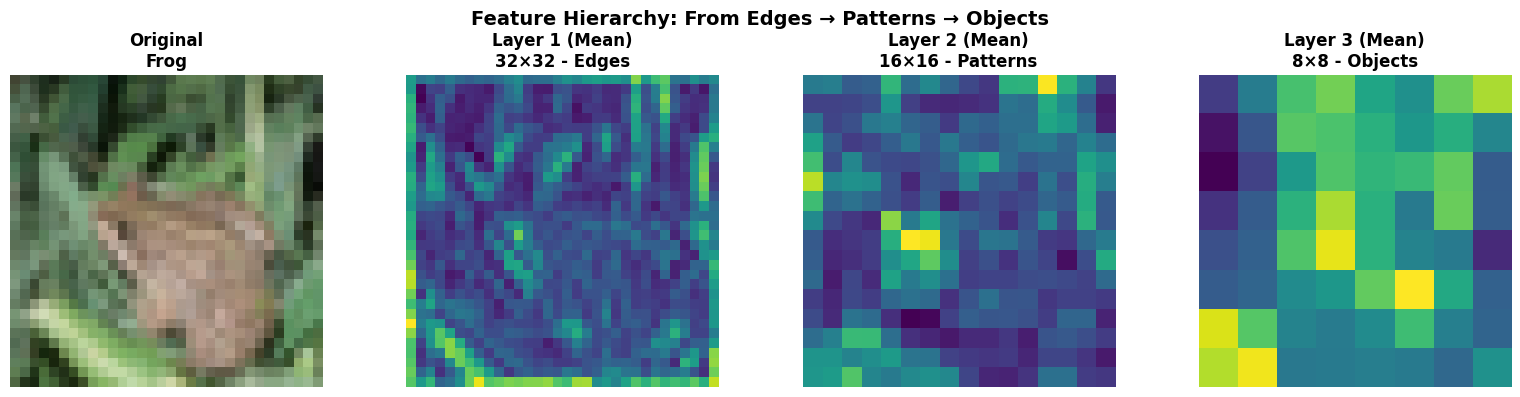


💡 Key Insight:
   • Early layers (L1): Low-level features (edges, colors)
   • Middle layers (L2): Mid-level features (textures, patterns)
   • Deep layers (L3): High-level features (object parts)
   • This hierarchy is how CNNs 'understand' images!


In [13]:
print("🔬 Comparing All Layers Side-by-Side\n")

# Get activations from all layers
l1_act = layer1_model.predict(test_image, verbose=0)
l2_act = layer2_model.predict(test_image, verbose=0)
l3_act = layer3_model.predict(test_image, verbose=0)

# Plot comparison - mean activation across all filters
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(X_test[test_idx])
axes[0].set_title(f'Original\n{class_names[test_label]}', fontweight='bold')
axes[0].axis('off')

axes[1].imshow(np.mean(l1_act[0], axis=-1), cmap='viridis')
axes[1].set_title('Layer 1 (Mean)\n32×32 - Edges', fontweight='bold')
axes[1].axis('off')

axes[2].imshow(np.mean(l2_act[0], axis=-1), cmap='viridis')
axes[2].set_title('Layer 2 (Mean)\n16×16 - Patterns', fontweight='bold')
axes[2].axis('off')

axes[3].imshow(np.mean(l3_act[0], axis=-1), cmap='viridis')
axes[3].set_title('Layer 3 (Mean)\n8×8 - Objects', fontweight='bold')
axes[3].axis('off')

plt.suptitle('Feature Hierarchy: From Edges → Patterns → Objects', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Key Insight:")
print("   • Early layers (L1): Low-level features (edges, colors)")
print("   • Middle layers (L2): Mid-level features (textures, patterns)")
print("   • Deep layers (L3): High-level features (object parts)")
print("   • This hierarchy is how CNNs 'understand' images!")

---
## 🔬 Cell 14: Visualize Learned Filters (Kernels)

🔬 Visualizing Learned Filters (What the CNN looks for)

Layer 1 filter shape: (3, 3, 3, 32)
  → 32 filters of size 3×3×3


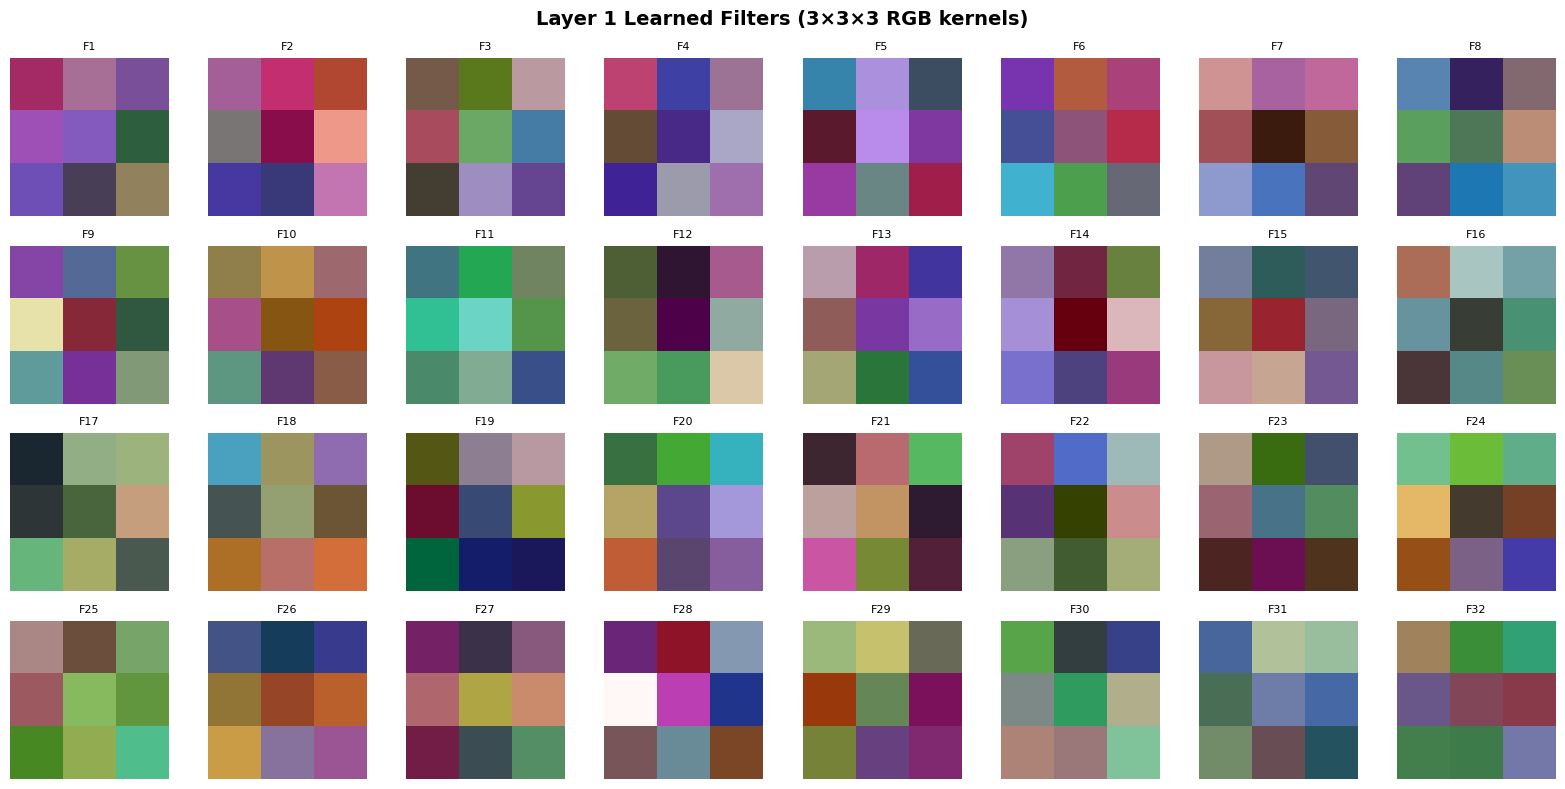


💡 These are the actual 3×3 kernels the CNN learned!
   • Each kernel detects a specific pattern
   • Colors show what RGB combinations activate each filter


In [14]:
print("🔬 Visualizing Learned Filters (What the CNN looks for)\n")

# Get weights from first conv layer
filters, biases = model.get_layer('conv1_1').get_weights()
print(f"Layer 1 filter shape: {filters.shape}")
print(f"  → {filters.shape[3]} filters of size {filters.shape[0]}×{filters.shape[1]}×{filters.shape[2]}")

# Normalize filters for visualization
f_min, f_max = filters.min(), filters.max()
filters_norm = (filters - f_min) / (f_max - f_min)

# Plot first 32 filters
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
axes = axes.flatten()

for i in range(32):
    # Get filter and display as RGB
    f = filters_norm[:, :, :, i]
    axes[i].imshow(f)
    axes[i].set_title(f'F{i+1}', fontsize=8)
    axes[i].axis('off')

plt.suptitle('Layer 1 Learned Filters (3×3×3 RGB kernels)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 These are the actual 3×3 kernels the CNN learned!")
print("   • Each kernel detects a specific pattern")
print("   • Colors show what RGB combinations activate each filter")

---
## 🔬 Cell 15: Compare Different Objects Through Layers

🔬 Comparing Different Objects Through CNN Layers



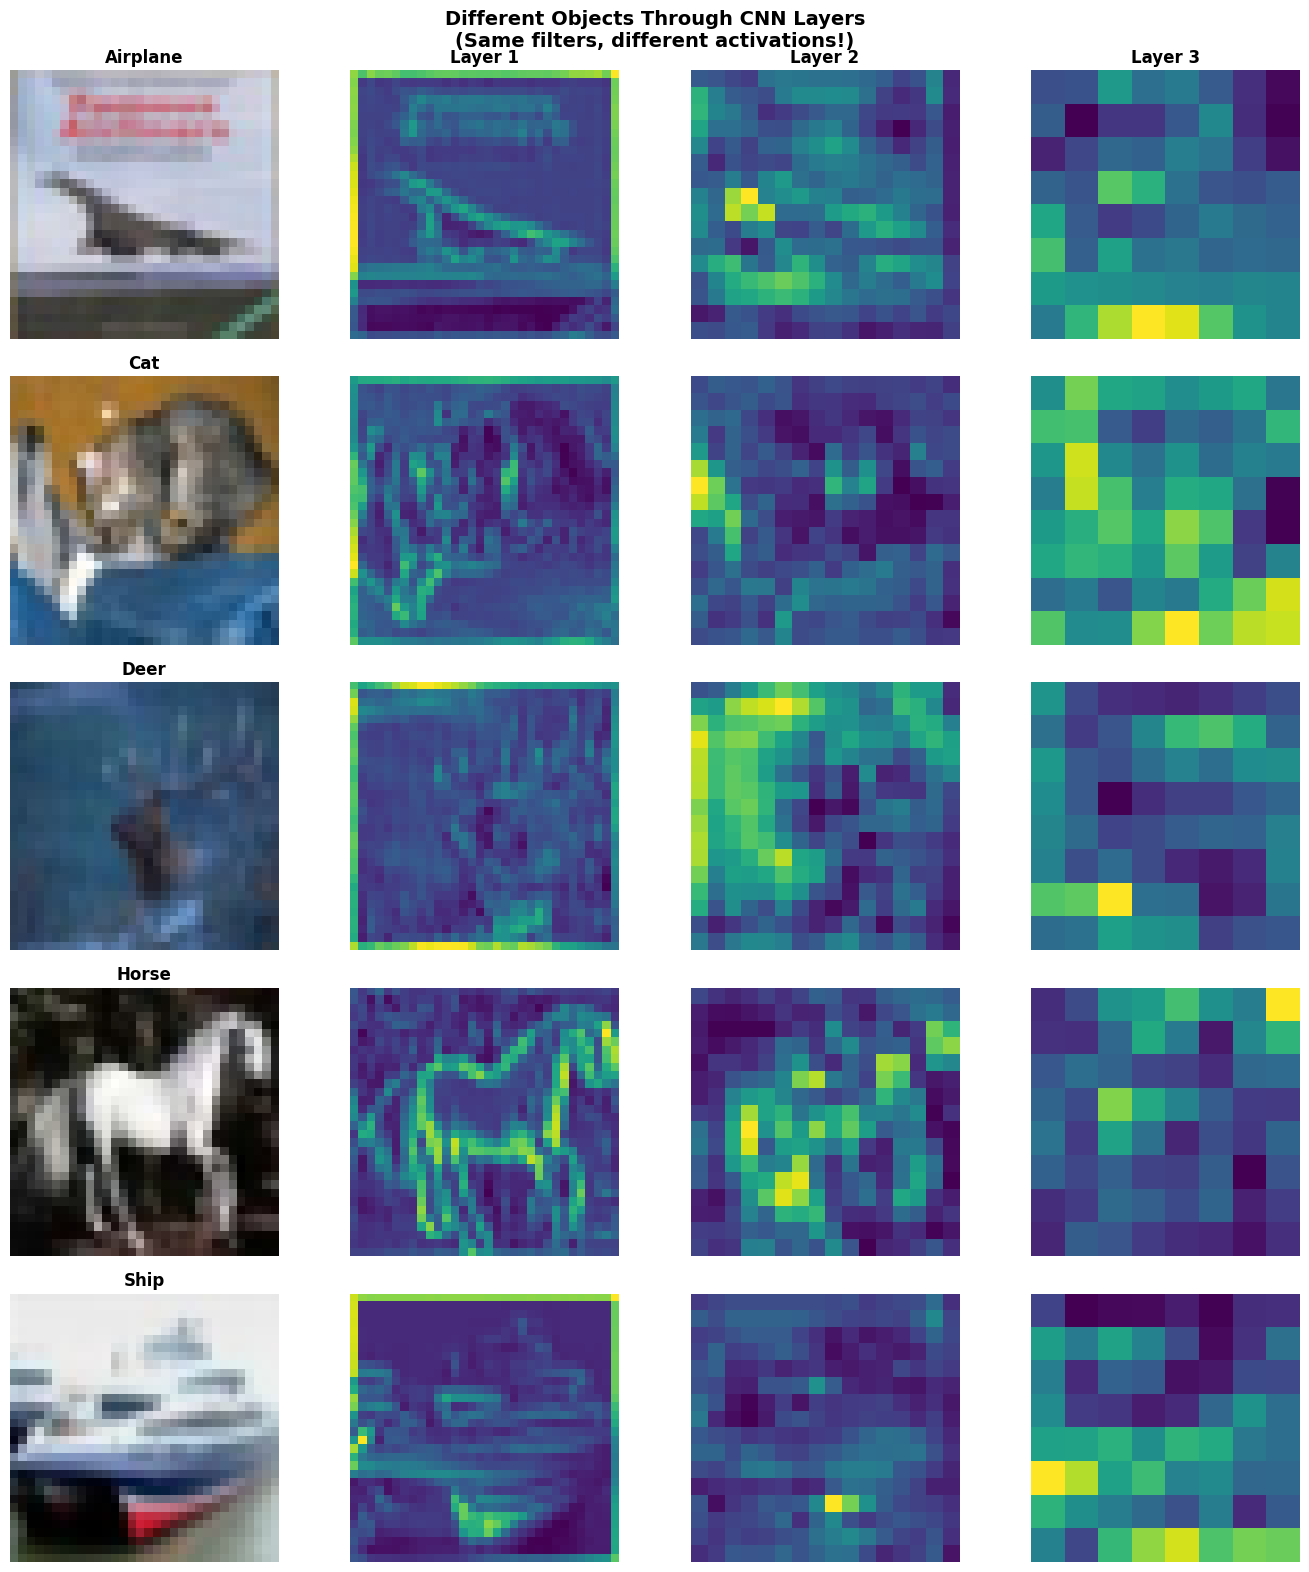


💡 Notice:
   • Same filters produce DIFFERENT activations for different objects
   • Animals activate different patterns than vehicles
   • This is how the CNN tells them apart!


In [15]:
print("🔬 Comparing Different Objects Through CNN Layers\n")

# Find one image from each of 5 categories
categories_to_show = [0, 3, 4, 7, 8]  # Airplane, Cat, Deer, Horse, Ship

fig, axes = plt.subplots(5, 4, figsize=(14, 16))

for row, cat in enumerate(categories_to_show):
    # Find image of this category
    idx = np.where(y_test.flatten() == cat)[0][0]
    img = X_test_norm[idx:idx+1]

    # Get activations
    l1 = layer1_model.predict(img, verbose=0)
    l2 = layer2_model.predict(img, verbose=0)
    l3 = layer3_model.predict(img, verbose=0)

    # Plot
    axes[row, 0].imshow(X_test[idx])
    axes[row, 0].set_title(f'{class_names[cat]}', fontweight='bold')
    axes[row, 0].axis('off')

    axes[row, 1].imshow(np.mean(l1[0], axis=-1), cmap='viridis')
    axes[row, 1].set_title('Layer 1' if row == 0 else '', fontweight='bold')
    axes[row, 1].axis('off')

    axes[row, 2].imshow(np.mean(l2[0], axis=-1), cmap='viridis')
    axes[row, 2].set_title('Layer 2' if row == 0 else '', fontweight='bold')
    axes[row, 2].axis('off')

    axes[row, 3].imshow(np.mean(l3[0], axis=-1), cmap='viridis')
    axes[row, 3].set_title('Layer 3' if row == 0 else '', fontweight='bold')
    axes[row, 3].axis('off')

plt.suptitle('Different Objects Through CNN Layers\n(Same filters, different activations!)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Notice:")
print("   • Same filters produce DIFFERENT activations for different objects")
print("   • Animals activate different patterns than vehicles")
print("   • This is how the CNN tells them apart!")

---
## 🎯 Cell 16: Test on Random Images

🎯 Testing on Random Images



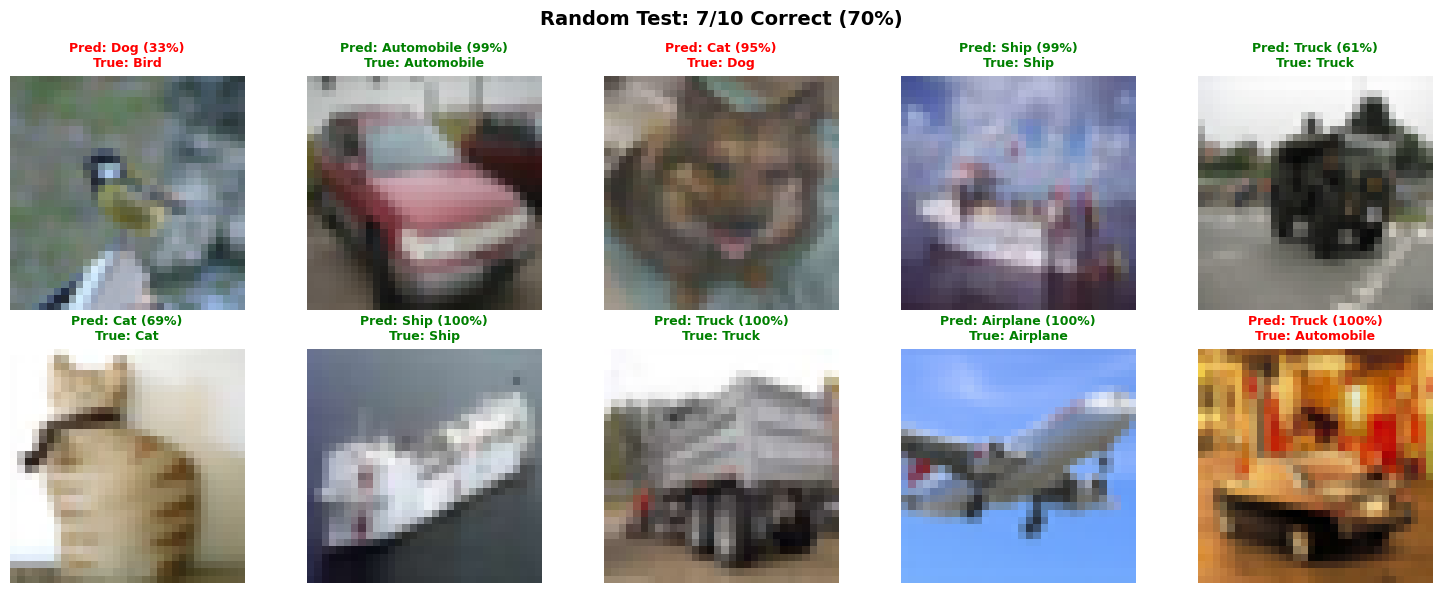


🔄 Run this cell again to see different random images!


In [16]:
print("🎯 Testing on Random Images\n")

# Pick 10 random test images
random_indices = np.random.choice(len(X_test), 10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

correct = 0
for i, idx in enumerate(random_indices):
    img = X_test_norm[idx:idx+1]
    true_label = y_test[idx][0]

    # Predict
    pred = model.predict(img, verbose=0)
    pred_label = np.argmax(pred)
    confidence = pred[0][pred_label] * 100

    # Check if correct
    is_correct = pred_label == true_label
    correct += is_correct

    # Plot
    axes[i].imshow(X_test[idx])
    color = 'green' if is_correct else 'red'
    axes[i].set_title(f'Pred: {class_names[pred_label]} ({confidence:.0f}%)\n'
                      f'True: {class_names[true_label]}',
                      fontsize=9, color=color, fontweight='bold')
    axes[i].axis('off')

plt.suptitle(f'Random Test: {correct}/10 Correct ({correct*10}%)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n🔄 Run this cell again to see different random images!")

---
# 📤 UPLOAD YOUR OWN PHOTOS!

Upload any image and watch the CNN classify it!

In [17]:
# ============================================================================
# 📤 UPLOAD HELPER FUNCTIONS
# ============================================================================

# Where does the photo come from?
#  • In Google Colab: an upload button appears (cancel it to use the demo photo instead).
#  • In Jupyter / VS Code: put your own file names in MY_IMAGES below.
#  • With neither, the notebook makes a demo "photo" (a test image enlarged to 256×256) so every cell still runs.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

MY_IMAGES = []      # e.g. ["my_cat.jpg"]  (used when not in Colab)


def make_demo_photo(test_index=3, path='demo_photo.png'):
    """Enlarge one CIFAR-10 TEST image to 256×256 and save it, standing in for a photo you took."""
    from PIL import Image as _PILImage
    _PILImage.fromarray(X_test[test_index]).resize((256, 256), _PILImage.Resampling.BICUBIC).save(path)
    print(f"(Demo photo: test image #{test_index}, a {class_names[y_test[test_index][0]]}, enlarged to 256×256.)")
    return path


def get_images():
    """Return a list of image file names to classify."""
    if IN_COLAB:
        uploaded = files.upload()
        if uploaded:
            return list(uploaded.keys())
    if MY_IMAGES:
        return list(MY_IMAGES)
    print("(No upload, so using a demo photo. Add your own file names to MY_IMAGES, or run this in Colab to upload.)")
    return [make_demo_photo()]


def center_crop_square(pil_img):
    """Cut the largest centred square out of a photo. CIFAR-10 images are square and the object fills them;
    squashing a 4:3 photo straight to 32×32 would stretch everything sideways."""
    w, h = pil_img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return pil_img.crop((left, top, left + s, top + s))


def preprocess_uploaded_image(image_data):
    """Preprocess uploaded image for CIFAR-10 CNN."""
    # Open image
    img = Image.open(BytesIO(image_data))

    # Convert to RGB if needed
    if img.mode != 'RGB':
        img = img.convert('RGB')

    # Crop the centre square first (CIFAR-10 images are square), then shrink to 32x32
    img = center_crop_square(img)
    img = img.resize((32, 32), Image.Resampling.LANCZOS)

    # Convert to numpy array
    img_array = np.array(img)

    return img_array


def visualize_uploaded_through_layers(img_array):
    """Visualize uploaded image through all CNN layers."""

    # Normalize and add batch dimension
    img_norm = img_array.astype('float32') / 255.0
    img_batch = np.expand_dims(img_norm, axis=0)

    # Get activations from all layers
    l1_act = layer1_model.predict(img_batch, verbose=0)
    l2_act = layer2_model.predict(img_batch, verbose=0)
    l3_act = layer3_model.predict(img_batch, verbose=0)

    # Get prediction
    pred = model.predict(img_batch, verbose=0)
    pred_class = np.argmax(pred)
    confidence = pred[0][pred_class] * 100

    # Plot
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    # Top row: Original and mean activations
    axes[0, 0].imshow(img_array)
    axes[0, 0].set_title(f'Your Image\nPredicted: {class_names[pred_class]}\n({confidence:.1f}%)',
                         fontweight='bold', fontsize=10)
    axes[0, 0].axis('off')

    axes[0, 1].imshow(np.mean(l1_act[0], axis=-1), cmap='viridis')
    axes[0, 1].set_title('Layer 1 (Mean)\n32×32 - Edges', fontweight='bold')
    axes[0, 1].axis('off')

    axes[0, 2].imshow(np.mean(l2_act[0], axis=-1), cmap='viridis')
    axes[0, 2].set_title('Layer 2 (Mean)\n16×16 - Patterns', fontweight='bold')
    axes[0, 2].axis('off')

    axes[0, 3].imshow(np.mean(l3_act[0], axis=-1), cmap='viridis')
    axes[0, 3].set_title('Layer 3 (Mean)\n8×8 - Objects', fontweight='bold')
    axes[0, 3].axis('off')

    # Bottom row: Individual filters
    axes[1, 0].text(0.5, 0.5, 'Individual\nFilters\n↓', ha='center', va='center',
                    fontsize=14, transform=axes[1, 0].transAxes)
    axes[1, 0].axis('off')

    axes[1, 1].imshow(l1_act[0, :, :, 0], cmap='viridis')
    axes[1, 1].set_title('L1 Filter 1', fontsize=10)
    axes[1, 1].axis('off')

    axes[1, 2].imshow(l2_act[0, :, :, 0], cmap='viridis')
    axes[1, 2].set_title('L2 Filter 1', fontsize=10)
    axes[1, 2].axis('off')

    axes[1, 3].imshow(l3_act[0, :, :, 0], cmap='viridis')
    axes[1, 3].set_title('L3 Filter 1', fontsize=10)
    axes[1, 3].axis('off')

    plt.suptitle('Your Image Through CNN Layers', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Show prediction probabilities
    print("\n📊 Prediction Probabilities:")
    top_5 = np.argsort(pred[0])[-5:][::-1]
    for idx in top_5:
        print(f"   {class_emojis[idx]} {class_names[idx]}: {pred[0][idx]*100:.1f}%")

    return pred_class, confidence


print("✅ Upload functions ready!")
print("\nRun the next cell to upload your image!")

✅ Upload functions ready!

Run the next cell to upload your image!


📤 Upload an image of one of these objects:
   ✈️ Airplane | 🚗 Automobile | 🐦 Bird | 🐱 Cat | 🦌 Deer
   🐕 Dog | 🐸 Frog | 🐴 Horse | 🚢 Ship | 🚚 Truck

(No upload, so using a demo photo. Add your own file names to MY_IMAGES, or run this in Colab to upload.)
(Demo photo: test image #3, a Airplane, enlarged to 256×256.)

✅ Image: demo_photo.png
⏳ Processing...



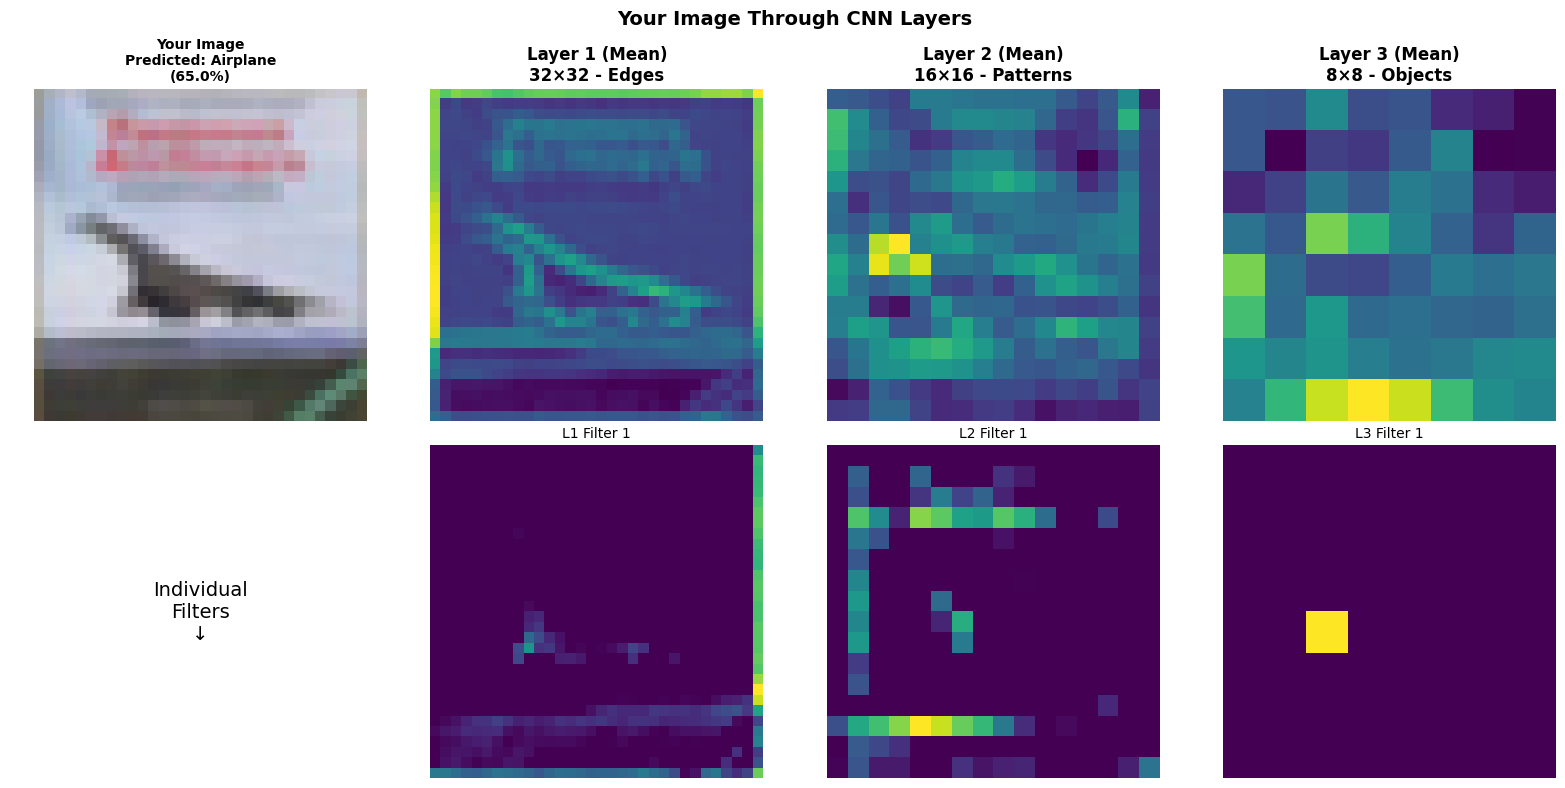


📊 Prediction Probabilities:
   ✈️ Airplane: 65.0%
   🚢 Ship: 33.4%
   🐱 Cat: 0.6%
   🐦 Bird: 0.5%
   🚚 Truck: 0.3%

🎯 Final Prediction: ✈️ Airplane (65.0%)


In [18]:
# ============================================================================
# 📤 UPLOAD YOUR IMAGE HERE!
# ============================================================================

print("📤 Upload an image of one of these objects:")
print("   ✈️ Airplane | 🚗 Automobile | 🐦 Bird | 🐱 Cat | 🦌 Deer")
print("   🐕 Dog | 🐸 Frog | 🐴 Horse | 🚢 Ship | 🚚 Truck")
print("")

for filename in get_images():
    image_data = open(filename, 'rb').read()
    print(f"\n✅ Image: {filename}")
    print("⏳ Processing...\n")

    # Preprocess (centre square, then 32×32)
    img_array = preprocess_uploaded_image(image_data)

    # Visualize through layers
    pred_class, confidence = visualize_uploaded_through_layers(img_array)

    print(f"\n🎯 Final Prediction: {class_emojis[pred_class]} {class_names[pred_class]} ({confidence:.1f}%)")

---
## 🧪 Experiments to Try!

### 1. **Change `test_idx`** in the visualization cells
   - Try different images and see how activations change

### 2. **Compare Animals vs Vehicles**
   - Do they activate different filters?

### 3. **Upload Different Photos**
   - Try photos from different angles
   - Try blurry photos - does the CNN still work?
   - Try photos with multiple objects

### 4. **Look for Patterns**
   - Which filters are "edge detectors"?
   - Which filters respond to colors?
   - How do layer 3 activations differ between classes?

### 5. **Test Edge Cases**
   - What happens with a photo that's NOT one of the 10 classes?
   - How confident is the CNN when it's wrong?

---
## 🎓 Summary: What We Learned

### CNN Feature Hierarchy:

| Layer | Size | What It Detects |
|-------|------|------------------|
| Layer 1 | 32×32 | Edges, colors, simple shapes |
| Layer 2 | 16×16 | Textures, patterns, combinations |
| Layer 3 | 8×8 | Object parts, high-level features |

### Key Insights:

1. **CNNs learn a hierarchy** - from simple to complex features
2. **Filters are learned** - not hand-designed
3. **Same filters, different activations** - that's how CNNs classify
4. **Deeper = more abstract** - harder to interpret but more powerful

### Why This Matters:

Understanding what CNNs "see" helps us:
- Debug models when they fail
- Design better architectures
- Trust AI decisions more
- Explain AI to others!

---

🎉 **Congratulations!** You've explored the inside of a CNN!

In [19]:
print("🎉 Great job exploring CNNs!")
print("")
print("📚 Key Takeaways:")
print("   1. CNNs learn hierarchical features automatically")
print("   2. Early layers → edges, colors")
print("   3. Middle layers → textures, patterns")
print("   4. Deep layers → object parts")
print("   5. Final layer → classification decision")
print("")
print("🚀 Next Steps:")
print("   • Try different architectures (VGG, ResNet)")
print("   • Explore transfer learning")
print("   • Learn about attention mechanisms")
print("   • Build your own image classifier!")

🎉 Great job exploring CNNs!

📚 Key Takeaways:
   1. CNNs learn hierarchical features automatically
   2. Early layers → edges, colors
   3. Middle layers → textures, patterns
   4. Deep layers → object parts
   5. Final layer → classification decision

🚀 Next Steps:
   • Try different architectures (VGG, ResNet)
   • Explore transfer learning
   • Learn about attention mechanisms
   • Build your own image classifier!
